# 14 — Forecasting h shots ahead, and the h = 1 leak

Two steps:
1. **Level only** (`scripts/level_forecast.py`): forecast the charge from the BCM history alone, with a GP on time
   (Matérn 5/2, + a periodic term on seg 5), Holt and the robust EMA.
2. **Everything known at t − h** (`scripts/feature_forecast.py`): BCM history plus every instrument, ridge /
   XGBoost / GRU over the last 32 known shots, pooled per regime, robust preparation.

Scores are the change of the test MAE against the challenge baseline, the mean of the last 9 good shots (negative =
better).

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parents[1] if Path.cwd().name == "adnan" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from regimes import load, score, REGIMES, NOISE_FLOOR_PCT
R = ROOT / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
REG_COL = {"low": "tab:blue", "high_rep": "tab:orange", "high_nonrep": "tab:green"}
SEG_ORDER = [0, 3, 4, 5, 1, 6, 7]
def segcols(df):
    return [c for c in SEG_ORDER if c in set(df.columns.get_level_values(-1))]

In [2]:
lv = pd.read_csv(R / "level_forecast_v1/scores.csv")
base = lv[lv.model == "mean9 (baseline)"].set_index(["segment", "h"])["mae_nC"]
lv["vs_baseline_pct"] = 100 * (lv.mae_nC / base.reindex(pd.MultiIndex.from_frame(lv[["segment", "h"]])).to_numpy() - 1)
lv["model"] = lv["model"].str.replace("gp periodic", "gp")
lv.pivot_table(index=["h", "model"], columns="segment", values="vs_baseline_pct")[SEG_ORDER].round(1)

segment                   0     3    4    5    1     6    7
h  model                                                   
1  gp                  -3.9  -1.1 -1.1 -1.7 -1.9   1.6 -4.5
   holt a=0.05,b=0.001 -5.5  -3.4  0.2 -1.9 -1.5  -1.0 -3.8
   mean9 (baseline)     0.0   0.0  0.0  0.0  0.0   0.0  0.0
   robust_ema hl=25    -5.9  -4.1  5.7  1.3  3.3  -1.2 -3.4
10 gp                  -6.4  -3.3 -0.9 -1.0 -3.3  -7.8 -0.2
   holt a=0.05,b=0.001 -6.8  -4.9  0.5 -1.0 -1.4  -9.9 -0.3
   mean9 (baseline)     0.0   0.0  0.0  0.0  0.0   0.0  0.0
   robust_ema hl=25    -7.7  -7.0  6.1  2.0  3.0 -11.6  0.6
50 gp                  -3.3  -8.1 -2.7  0.3 -2.4  -5.1 -3.1
   holt a=0.05,b=0.001 -3.9  -9.8  2.6 -1.2  2.2  -6.4 -0.5
   mean9 (baseline)     0.0   0.0  0.0  0.0  0.0   0.0  0.0
   robust_ema hl=25    -4.3 -11.4  7.4  1.0  6.5  -7.0  1.6

In [3]:
lp = pd.read_csv(R / "level_forecast_periodic190/scores.csv")
lp["vs_baseline_pct"] = 100 * (lp.mae_nC / base.reindex(pd.MultiIndex.from_frame(lp[["segment", "h"]])).to_numpy() - 1)
cmp = pd.concat({"GP": lv[lv.model == "gp"].pivot_table(index="h", columns="segment", values="vs_baseline_pct")[[5, 1]],
                 "GP + ~190-shot cycle": lp[lp.model == "gp"].pivot_table(index="h", columns="segment", values="vs_baseline_pct")[[5, 1]]}, axis=1)
cmp.round(1)

GP      GP + ~190-shot cycle     
segment    5    1                    5    1
h                                          
1       -1.7 -1.9                 -1.7 -2.2
10      -1.0 -3.3                 -0.8 -2.8
50       0.3 -2.4                  3.9  1.9

**Reading (history only).**
- The GP beats the 9-shot mean on 6/7 segments at h = 1 and 50 and on all 7 at h = 10, by 1–8 %.
- The robust EMA, best for the decomposition (notebook 12), is a poor forecaster: up to +7 % at h = 50 on seg 4.
  The best level for removing the trend is not the best guess of the next level.
- **Negative result:** adding the ~190-shot cycle seen in the spectra does not help at h ≤ 10 and hurts at h = 50
  (seg 5 +3.9 %, seg 1 +1.9 %). The cycle is there, but its phase does not hold long enough to extrapolate.

## The h = 1 leak in `results/datasets`

First run of the feature forecaster: with the instruments, the next-shot error fell by 17–20 % on segs 5 and 7, against
2–4 % from the history alone. A gain that collapses between h = 1 and h = 2 means future data.

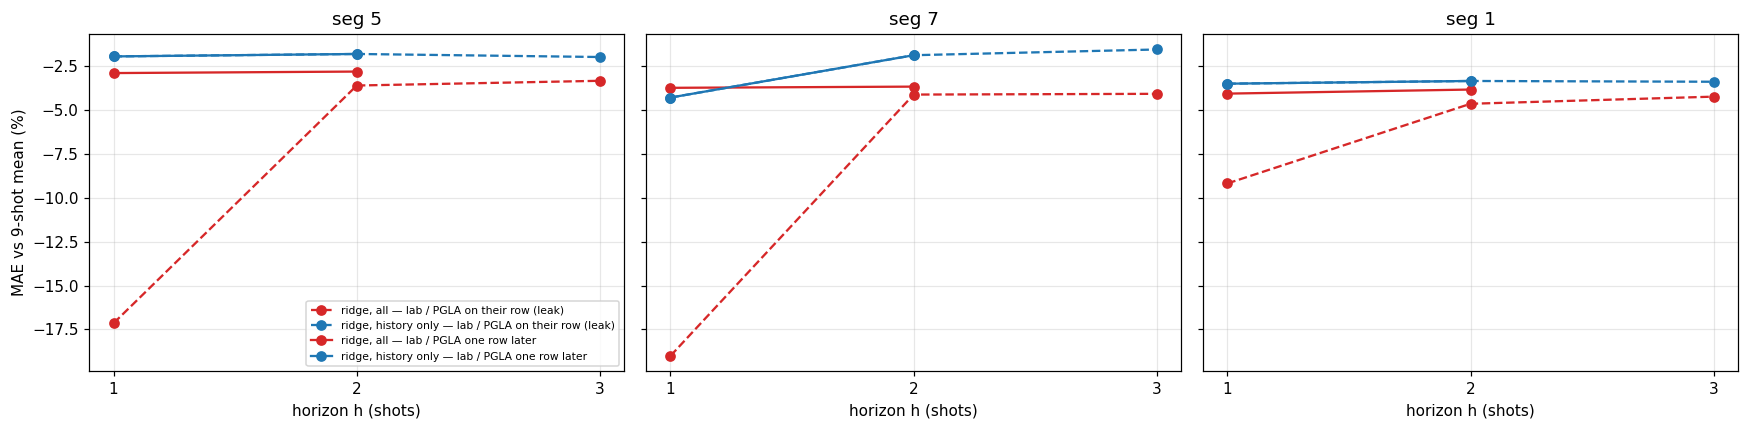

In [4]:
leak = pd.read_csv(R / "feature_forecast_leak/scores.csv")
fixed = pd.read_csv(R / "feature_forecast/scores.csv")
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, s in zip(axes, (5, 7, 1)):
    for d, tag, ls in ((leak, "lab / PGLA on their row (leak)", "--"), (fixed[fixed.h <= 3], "lab / PGLA one row later", "-")):
        for mname, c in (("ridge, all", "tab:red"), ("ridge, history only", "tab:blue")):
            q = d[(d.segment == s) & (d.model == mname)].sort_values("h")
            ax.plot(q.h, q.vs_baseline_pct, ls, marker="o", color=c, label=f"{mname} — {tag}")
    ax.set_title(f"seg {s}"); ax.set_xlabel("horizon h (shots)"); ax.set_xticks([1, 2, 3])
axes[0].set_ylabel("MAE vs 9-shot mean (%)"); axes[0].legend(fontsize=7)
fig.tight_layout()

In [5]:
segs, names = load(R.parent / "results/datasets", robust=5)
rows = []
for s in (7, 5, 1, 6):
    g = segs[s]; j = g["jitter"]; m = g["good"] & np.isfinite(j)
    for f in ("lab_laser_power", "PGLA_drop", "BTV_intensity"):
        x = g["Xfast"][:, names.index(f)]; r = {}
        for k in (0, 1, 2):
            a = np.r_[np.zeros(k), x[: len(x) - k]]; mm = m & (a != 0)
            r[f"row t-{k}" if k else "row t"] = np.corrcoef(j[mm], a[mm])[0, 1]
        rows.append({"segment": s, "feature": f, **r})
pd.DataFrame(rows).set_index(["segment", "feature"]).round(2)

row t  row t-1  row t-2
segment feature                                 
7       lab_laser_power   0.34     0.56     0.13
        PGLA_drop         0.17     0.21     0.05
        BTV_intensity     0.79     0.14     0.08
5       lab_laser_power   0.17     0.18     0.07
        PGLA_drop         0.06     0.07     0.05
        BTV_intensity     0.27     0.06     0.04
1       lab_laser_power   0.51     0.43     0.18
        PGLA_drop         0.11     0.08     0.02
        BTV_intensity     0.83     0.21     0.14
6       lab_laser_power   0.86     0.19     0.13
        PGLA_drop         0.16     0.04     0.01
        BTV_intensity     0.82     0.15     0.10

**Reading.** In `results/datasets` the lab meter (and PGLA_drop) on row t − 1 correlates with shot t's charge
jitter as much as or more than row t does (seg 7: 0.56 against 0.34). On part of the rows the column holds the
*next* shot's reading: the `meter_shift` rule of `scripts/pulses.py` (a reading taken < 2.2 s after the trigger
belongs to the previous pulse) is not applied per shot by `extract_features.py`. The camera has no such excess.
`feature_forecast.py` therefore uses those two columns one row later. **This also affects the same-shot models of the
team datasets: the lab column mixes shots t and t + 1.** The fix belongs in `extract_features.py`.

## Forecast skill against the horizon (leak removed)

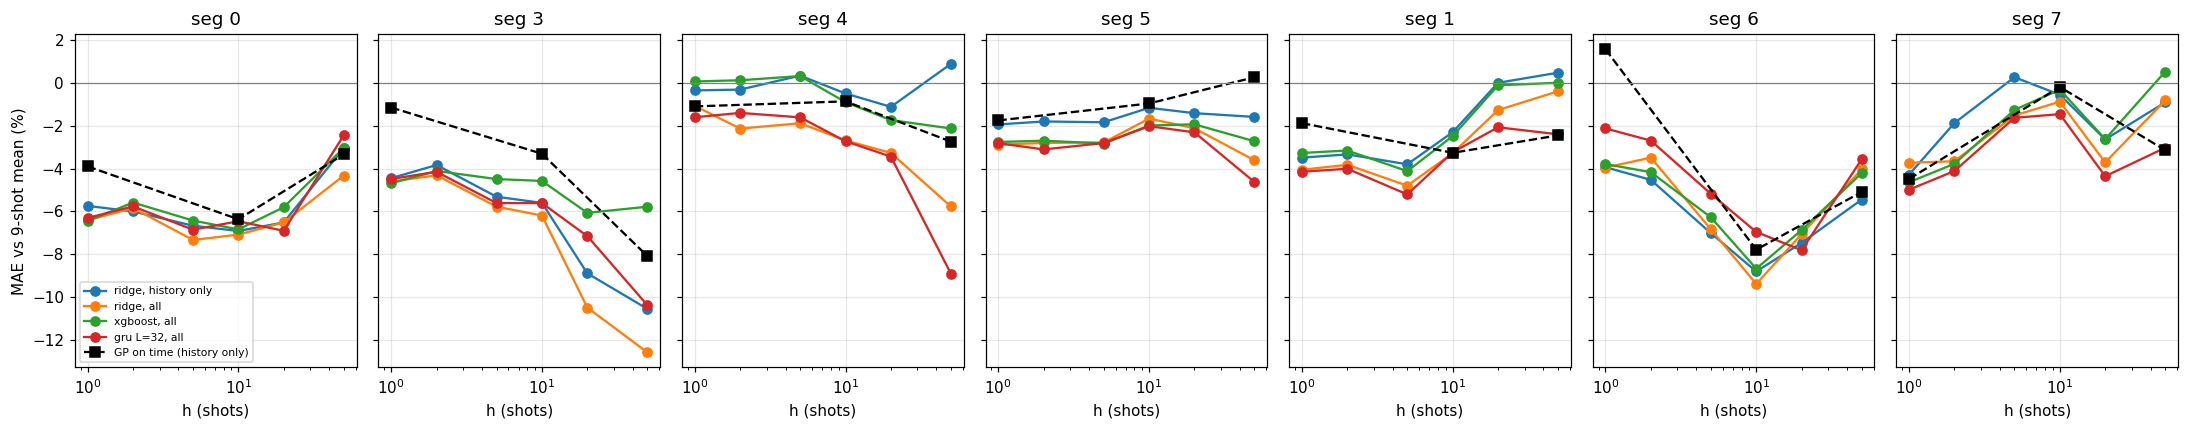

In [6]:
order = ["ridge, history only", "ridge, all", "xgboost, all", "gru L=32, all"]
fig, axes = plt.subplots(1, 7, figsize=(20, 4), sharey=True)
for ax, s in zip(axes, SEG_ORDER):
    for mname in order:
        q = fixed[(fixed.segment == s) & (fixed.model == mname)].sort_values("h")
        ax.plot(q.h, q.vs_baseline_pct, "o-", label=mname)
    g = lv[(lv.segment == s) & (lv.model == "gp")].sort_values("h")
    ax.plot(g.h, g.vs_baseline_pct, "k--", marker="s", label="GP on time (history only)")
    ax.axhline(0, color="0.5", lw=0.8); ax.set_xscale("log"); ax.set_title(f"seg {s}"); ax.set_xlabel("h (shots)")
axes[0].set_ylabel("MAE vs 9-shot mean (%)"); axes[0].legend(fontsize=7)
fig.tight_layout()

In [7]:
fixed.pivot_table(index=["h", "model"], columns="segment", values="vs_baseline_pct")[SEG_ORDER].round(1)

segment                   0     3    4    5    1    6    7
h  model                                                  
1  gru L=32, all       -6.3  -4.5 -1.6 -2.8 -4.1 -2.1 -5.0
   mean9 (baseline)     0.0   0.0  0.0  0.0  0.0  0.0  0.0
   ridge, all          -6.4  -4.6 -1.1 -2.9 -4.1 -3.9 -3.7
   ridge, history only -5.7  -4.4 -0.3 -1.9 -3.5 -3.9 -4.3
   xgboost, all        -6.4  -4.7  0.1 -2.8 -3.3 -3.8 -4.6
2  gru L=32, all       -5.8  -4.1 -1.4 -3.1 -4.0 -2.7 -4.1
   mean9 (baseline)     0.0   0.0  0.0  0.0  0.0  0.0  0.0
   ridge, all          -5.8  -4.3 -2.1 -2.8 -3.8 -3.5 -3.7
   ridge, history only -6.0  -3.8 -0.3 -1.8 -3.3 -4.5 -1.9
   xgboost, all        -5.6  -4.1  0.1 -2.7 -3.2 -4.2 -3.8
5  gru L=32, all       -6.9  -5.6 -1.6 -2.8 -5.2 -5.2 -1.6
   mean9 (baseline)     0.0   0.0  0.0  0.0  0.0  0.0  0.0
   ridge, all          -7.3  -5.8 -1.9 -2.8 -4.8 -6.8 -1.5
   ridge, history only -6.7  -5.3  0.4 -1.8 -3.8 -7.0  0.3
   xgboost, all        -6.4  -4.5  0.3 -2.8 -4.1 -6.3 -1.3
10 gru L=32, all       -6.5  -5.6 -2.7 -2.0 -3.2 -7.0 -1.5
   mean9 (baseline)     0.0   0.0  0.0  0.0  0.0  0.0  0.0
   ridge, all          -7.1  -6.2 -2.7 -1.7 -3.3 -9.4 -0.9
   ridge, history only -6.9  -5.6 -0.5 -1.2 -2.3 -8.8 -0.5
   xgboost, all        -6.8  -4.6 -0.9 -2.0 -2.5 -8.7 -0.3
20 gru L=32, all       -6.9  -7.2 -3.4 -2.3 -2.1 -7.8 -4.4
   mean9 (baseline)     0.0   0.0  0.0  0.0  0.0  0.0  0.0
   ridge, all          -6.5 -10.5 -3.3 -2.1 -1.3 -7.1 -3.7
   ridge, history only -6.5  -8.9 -1.1 -1.4  0.0 -7.5 -2.6
   xgboost, all        -5.8  -6.1 -1.7 -1.9 -0.1 -6.9 -2.6
50 gru L=32, all       -2.4 -10.4 -8.9 -4.6 -2.4 -3.6 -3.0
   mean9 (baseline)     0.0   0.0  0.0  0.0  0.0  0.0  0.0
   ridge, all          -4.3 -12.6 -5.8 -3.6 -0.4 -4.0 -0.8
   ridge, history only -3.0 -10.6  0.9 -1.6  0.5 -5.5 -0.9
   xgboost, all        -3.0  -5.8 -2.1 -2.7  0.0 -4.2  0.5

**Reading.**
- Every model beats the 9-shot mean at every horizon on almost every segment, by a few percent.
- The instruments add 0.5–2 points over the BCM history at short horizons; the gain does not grow with h.
- This matches the team's earlier conclusion: the shot-to-shot jitter is laser-driven and the next pulse's laser
  energy is not predictable. What forecasting can do is track the level better than a 9-shot mean.
- The same-shot virtual diagnostic (notebooks 11 and 13) is where the instruments pay: 60–90 % of the jitter
  explained at high charge.